# Diabetes Prediction using Machine Learning

**Dataset:** `diabetes_prediction_dataset.csv` (100,000 records, 9 columns)
**Target variable:** `diabetes` (0 = No diabetes, 1 = Diabetes)

## 1. Importing the libraries

In [1]:
# Import data handling libraries
import pandas as pd
import numpy as np

# Import visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import general utilities
import os
import json
import time
import shutil
import warnings
import joblib
import sklearn

# Import preprocessing and pipeline tools
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Import the machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

# Import evaluation tools
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

# Hide warning messages for a cleaner output
warnings.filterwarnings('ignore')

# Set the default plot style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.titlesize'] = 13

# Set a fixed random seed so results are reproducible
RANDOM_STATE = 42

# Create a folder to store all output files (model, plots, metadata)
os.makedirs('outputs', exist_ok=True)
os.makedirs('outputs/plots', exist_ok=True)

## 2. Loading the dataset

In [2]:
# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/content/diabetes_prediction_dataset.csv')

# Display the first five rows
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 3. Data inspection

### 3.1 Shape of the dataset

In [3]:
# Print the number of rows and columns
print('Rows   :', df.shape[0])
print('Columns:', df.shape[1])

Rows   : 100000
Columns: 9


### 3.2 Column names and data types

In [4]:
# Show column names, data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


### 3.3 Statistical summary of numerical columns

In [5]:
# Show count, mean, std, min, quartiles and max for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.074850,0.263150,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039420,0.194593,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085000,0.278883,0.00,0.00,0.00,0.00,1.00


### 3.4 Summary of categorical columns

In [6]:
# Show the unique values and frequency of the categorical columns
df.describe(include='object').T

,count,unique,top,freq
gender,100000,3,Female,58552
smoking_history,100000,6,No Info,35816


### 3.5 Checking missing values

In [7]:
# Count missing values in each column
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


### 3.6 Checking duplicate rows

In [8]:
# Count fully duplicated rows
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 3854


### 3.7 Checking categories in each categorical column

In [9]:
# Print the value counts of gender and smoking history
for col in ['gender', 'smoking_history']:
    print(df[col].value_counts(), '\n')

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64 

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64 



### 3.8 Checking the target variable

In [10]:
# Show the count and percentage of each class in the target
print(df['diabetes'].value_counts(), '\n')
print((df['diabetes'].value_counts(normalize=True) * 100).round(2))

diabetes
0    91500
1     8500
Name: count, dtype: int64 

diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


## 4. Data cleaning

### 4.1 Removing duplicate rows


In [11]:
# Store the row count before cleaning
rows_before = len(df)

# Drop the duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Show how many rows were removed
print('Rows before:', rows_before)
print('Rows after :', len(df))
print('Removed    :', rows_before - len(df))

Rows before: 100000
Rows after : 96146
Removed    : 3854


### 4.2 Handling the rare gender category


In [12]:
# Count the rows with gender 'Other'
print('Rows with gender Other:', (df['gender'] == 'Other').sum())

# Keep only Female and Male records
df = df[df['gender'].isin(['Female', 'Male'])].reset_index(drop=True)

# Confirm the remaining categories
print(df['gender'].value_counts())

Rows with gender Other: 18
gender
Female    56161
Male      39967
Name: count, dtype: int64


### 4.3 Reviewing the smoking history column


In [13]:
# Show the smoking history categories that will be used in the model
print(df['smoking_history'].value_counts())

smoking_history
never          34395
No Info        32881
former          9299
current         9197
not current     6359
ever            3997
Name: count, dtype: int64


### 4.4 Checking outliers with the IQR method


In [14]:
# Define the numerical columns
numeric_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# Count the outliers in each numerical column using the IQR rule
outlier_summary = {}
for col in numeric_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_summary[col] = int(((df[col] < lower) | (df[col] > upper)).sum())

# Display the outlier counts
pd.Series(outlier_summary, name='outlier_count')

,outlier_count
age,0
bmi,5354
HbA1c_level,1312
blood_glucose_level,2031


### 4.5 Final check of the cleaned data

In [15]:
# Confirm the shape and that no missing values remain
print('Cleaned shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
print('Duplicates    :', df.duplicated().sum())

Cleaned shape: (96128, 9)
Missing values: 0
Duplicates    : 0


## 5. Exploratory data analysis (EDA)


### 5.1 Target variable distribution

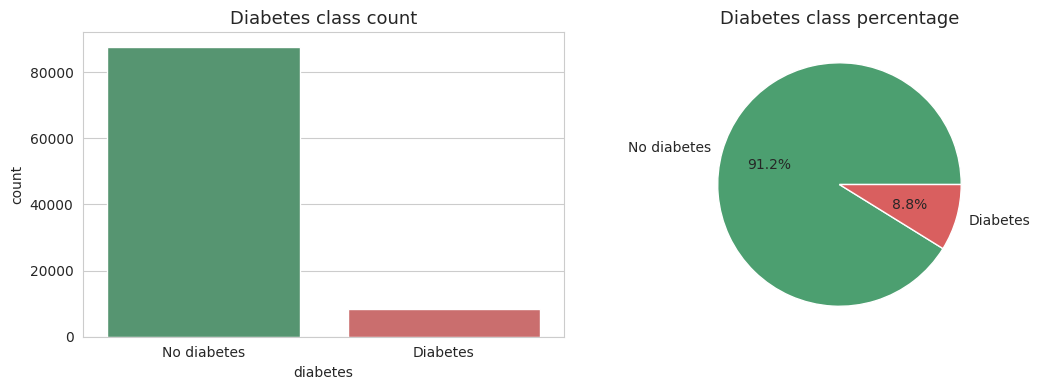

In [16]:
# Create a count plot of the target variable
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='diabetes', data=df, palette=['#4C9F70', '#D95F5F'], ax=ax[0])
ax[0].set_title('Diabetes class count')
ax[0].set_xticklabels(['No diabetes', 'Diabetes'])

# Add a pie chart showing the class percentages
df['diabetes'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#4C9F70', '#D95F5F'],
                                       labels=['No diabetes', 'Diabetes'], ax=ax[1])
ax[1].set_ylabel('')
ax[1].set_title('Diabetes class percentage')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_target_distribution.png', dpi=150)
plt.show()

### 5.2 Distribution of numerical features

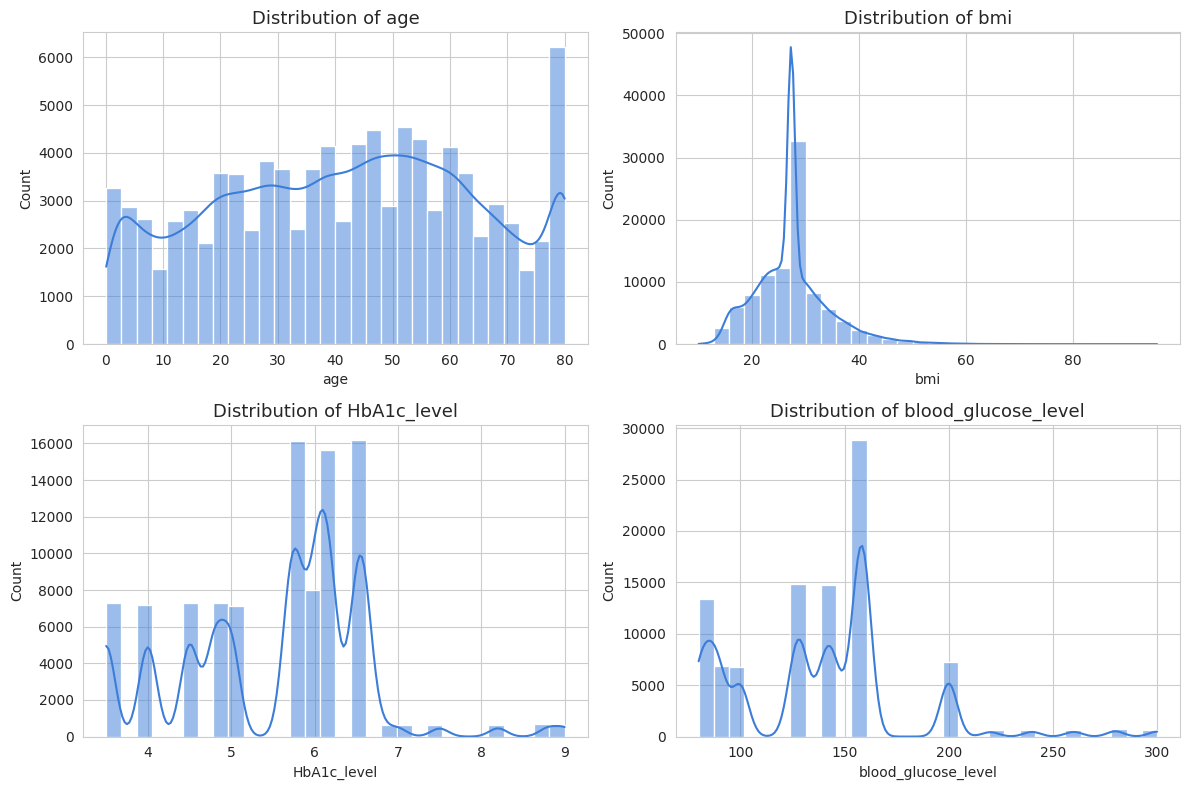

In [17]:
# Plot a histogram with a density curve for each numerical feature
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(df[col], kde=True, bins=30, color='#3B7DD8', ax=ax)
    ax.set_title(f'Distribution of {col}')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_numeric_distributions.png', dpi=150)
plt.show()

### 5.3 Outlier detection using boxplots

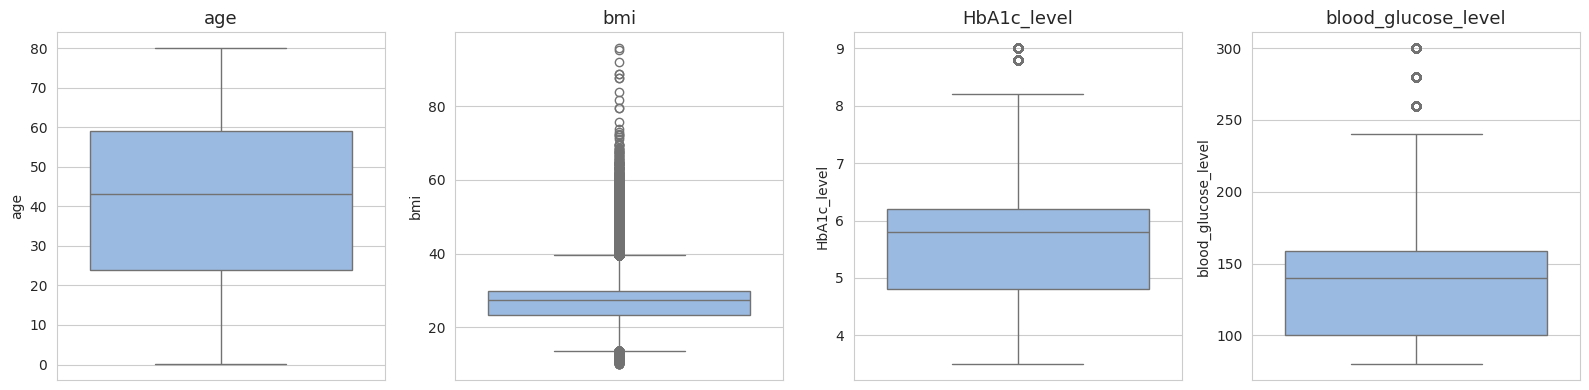

In [18]:
# Draw a boxplot for each numerical feature
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], color='#8FB8ED', ax=ax)
    ax.set_title(col)

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_boxplots_outliers.png', dpi=150)
plt.show()

### 5.4 Distribution of categorical features

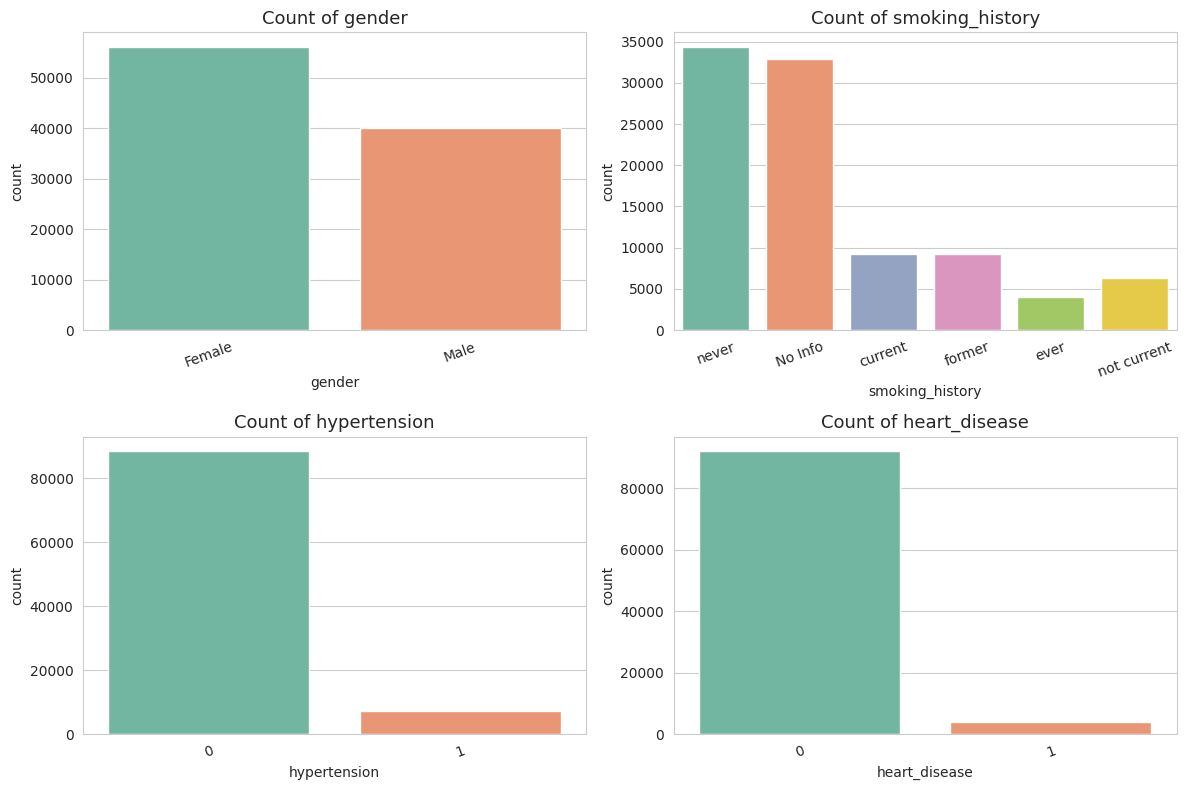

In [19]:
# Define the categorical and binary columns
cat_plot_cols = ['gender', 'smoking_history', 'hypertension', 'heart_disease']

# Plot the count of each category
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_plot_cols):
    sns.countplot(x=col, data=df, palette='Set2', ax=ax)
    ax.set_title(f'Count of {col}')
    ax.tick_params(axis='x', rotation=20)

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_categorical_counts.png', dpi=150)
plt.show()

### 5.5 Diabetes rate by categorical feature

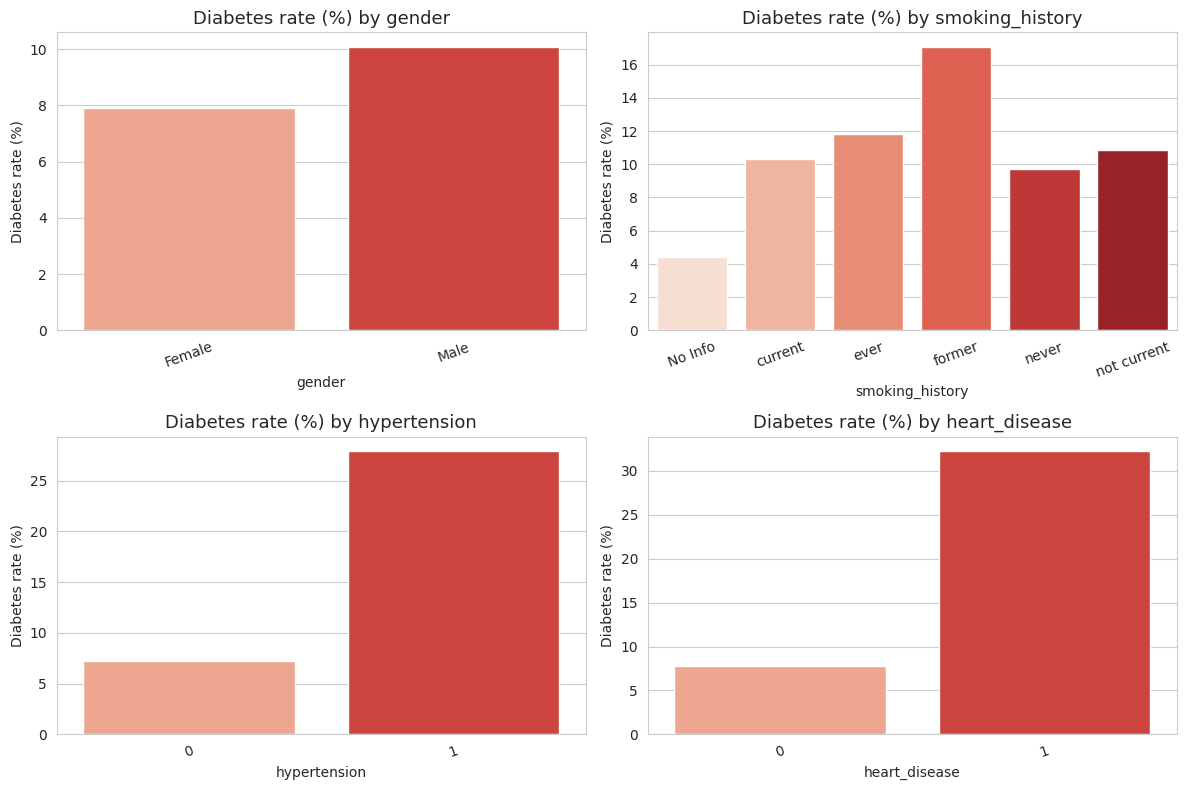

In [20]:
# Plot the percentage of diabetic patients within each category
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_plot_cols):
    rate = df.groupby(col)['diabetes'].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, palette='Reds', ax=ax)
    ax.set_title(f'Diabetes rate (%) by {col}')
    ax.set_ylabel('Diabetes rate (%)')
    ax.set_xlabel(col)
    ax.tick_params(axis='x', rotation=20)

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_diabetes_rate_categorical.png', dpi=150)
plt.show()

### 5.6 Numerical features compared by diabetes status (boxplots)

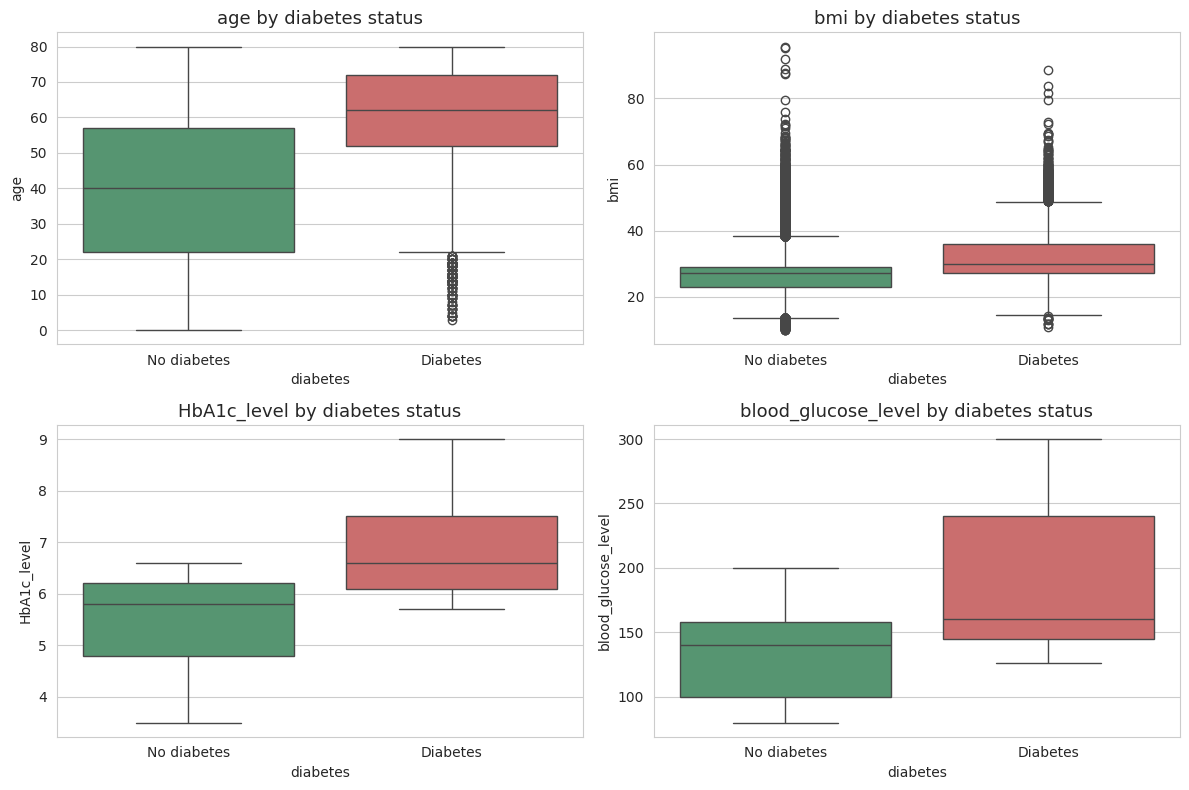

In [21]:
# Compare each numerical feature between diabetic and non-diabetic patients
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.boxplot(x='diabetes', y=col, data=df, palette=['#4C9F70', '#D95F5F'], ax=ax)
    ax.set_xticklabels(['No diabetes', 'Diabetes'])
    ax.set_title(f'{col} by diabetes status')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_numeric_by_target_boxplot.png', dpi=150)
plt.show()

### 5.7 Density comparison by diabetes status

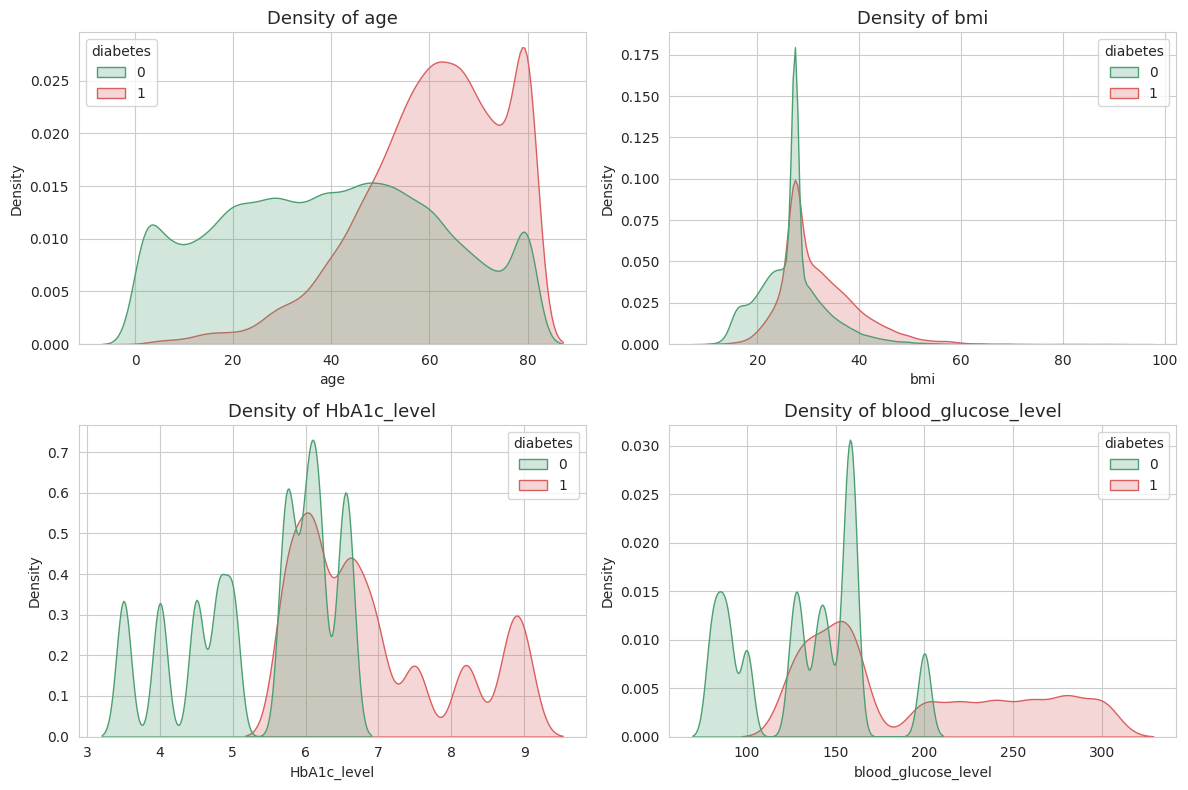

In [22]:
# Plot overlapping density curves for each numerical feature
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.kdeplot(data=df, x=col, hue='diabetes', fill=True, common_norm=False,
                palette=['#4C9F70', '#D95F5F'], ax=ax)
    ax.set_title(f'Density of {col}')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_density_by_target.png', dpi=150)
plt.show()

### 5.8 Diabetes rate by age group

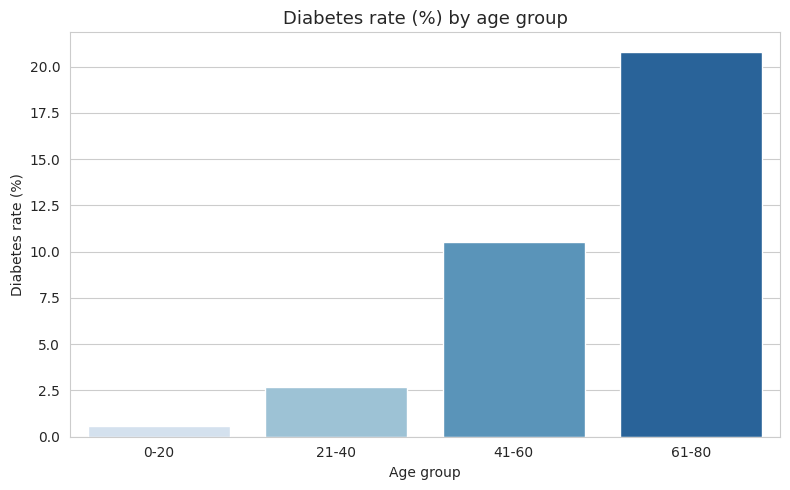

In [23]:
# Group patients into age bands
age_bins = [0, 20, 40, 60, 80]
age_labels = ['0-20', '21-40', '41-60', '61-80']
age_group = pd.cut(df['age'], bins=age_bins, labels=age_labels)

# Calculate the diabetes rate for each age band
age_rate = df.groupby(age_group)['diabetes'].mean() * 100

# Plot the diabetes rate by age band
sns.barplot(x=age_rate.index.astype(str), y=age_rate.values, palette='Blues')
plt.title('Diabetes rate (%) by age group')
plt.xlabel('Age group')
plt.ylabel('Diabetes rate (%)')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_age_group_rate.png', dpi=150)
plt.show()

### 5.9 Diabetes rate by BMI category

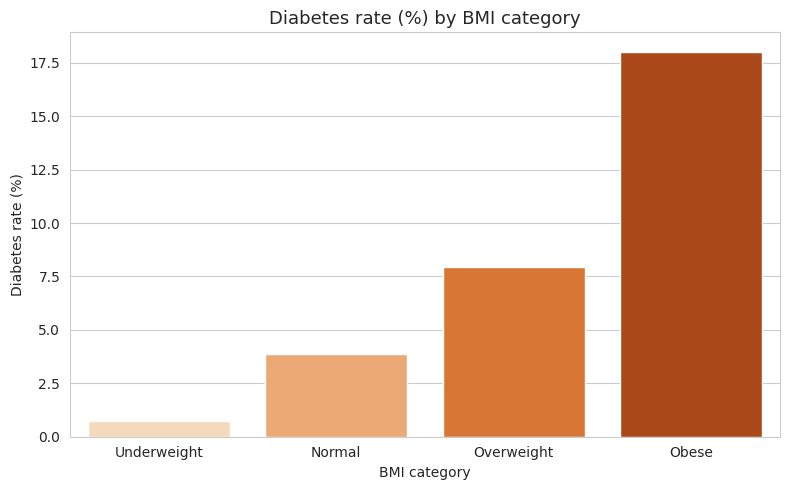

In [24]:
# Group patients into standard BMI categories
bmi_bins = [0, 18.5, 25, 30, 100]
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
bmi_group = pd.cut(df['bmi'], bins=bmi_bins, labels=bmi_labels)

# Calculate the diabetes rate for each BMI category
bmi_rate = df.groupby(bmi_group)['diabetes'].mean() * 100

# Plot the diabetes rate by BMI category
sns.barplot(x=bmi_rate.index.astype(str), y=bmi_rate.values, palette='Oranges')
plt.title('Diabetes rate (%) by BMI category')
plt.xlabel('BMI category')
plt.ylabel('Diabetes rate (%)')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_bmi_category_rate.png', dpi=150)
plt.show()

### 5.10 Diabetes rate by HbA1c level

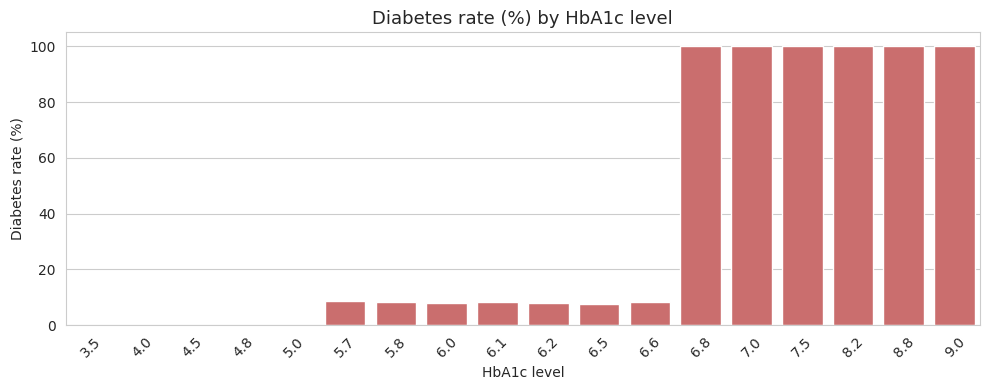

In [25]:
# Calculate the diabetes rate for each distinct HbA1c value
hba1c_rate = df.groupby('HbA1c_level')['diabetes'].mean() * 100

# Plot the diabetes rate for each HbA1c value
plt.figure(figsize=(10, 4))
sns.barplot(x=hba1c_rate.index.astype(str), y=hba1c_rate.values, color='#D95F5F')
plt.title('Diabetes rate (%) by HbA1c level')
plt.xlabel('HbA1c level')
plt.ylabel('Diabetes rate (%)')
plt.xticks(rotation=45)

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_hba1c_rate.png', dpi=150)
plt.show()

### 5.11 Diabetes rate by blood glucose level

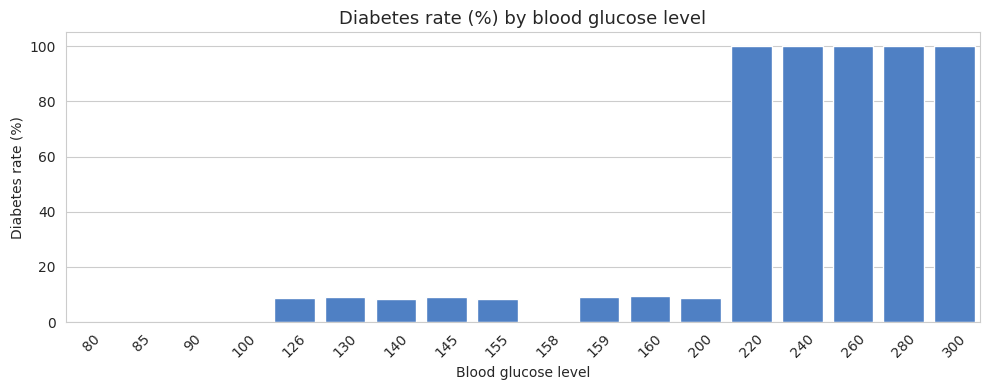

In [26]:
# Calculate the diabetes rate for each distinct blood glucose value
glucose_rate = df.groupby('blood_glucose_level')['diabetes'].mean() * 100

# Plot the diabetes rate for each blood glucose value
plt.figure(figsize=(10, 4))
sns.barplot(x=glucose_rate.index.astype(str), y=glucose_rate.values, color='#3B7DD8')
plt.title('Diabetes rate (%) by blood glucose level')
plt.xlabel('Blood glucose level')
plt.ylabel('Diabetes rate (%)')
plt.xticks(rotation=45)

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_glucose_rate.png', dpi=150)
plt.show()

### 5.12 HbA1c versus blood glucose

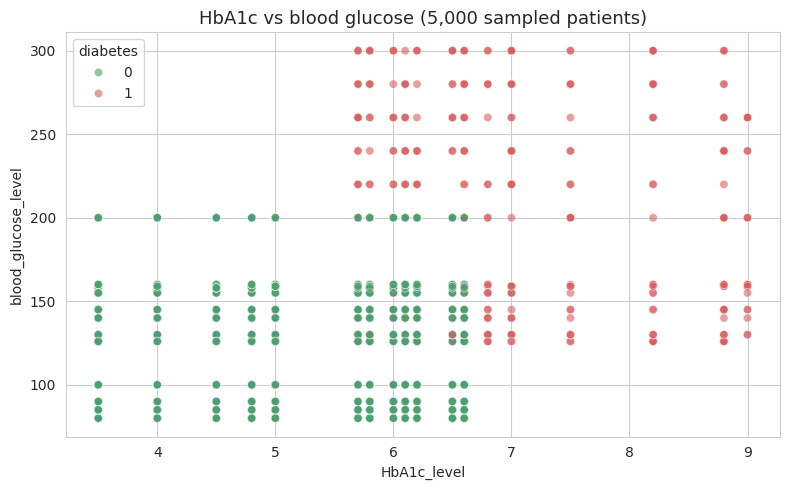

In [27]:
# Take a random sample so the scatter plot stays readable
sample_df = df.sample(5000, random_state=RANDOM_STATE)

# Plot HbA1c against blood glucose coloured by diabetes status
sns.scatterplot(data=sample_df, x='HbA1c_level', y='blood_glucose_level', hue='diabetes',
                palette=['#4C9F70', '#D95F5F'], alpha=0.6)
plt.title('HbA1c vs blood glucose (5,000 sampled patients)')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_hba1c_vs_glucose.png', dpi=150)
plt.show()

### 5.13 Age versus BMI

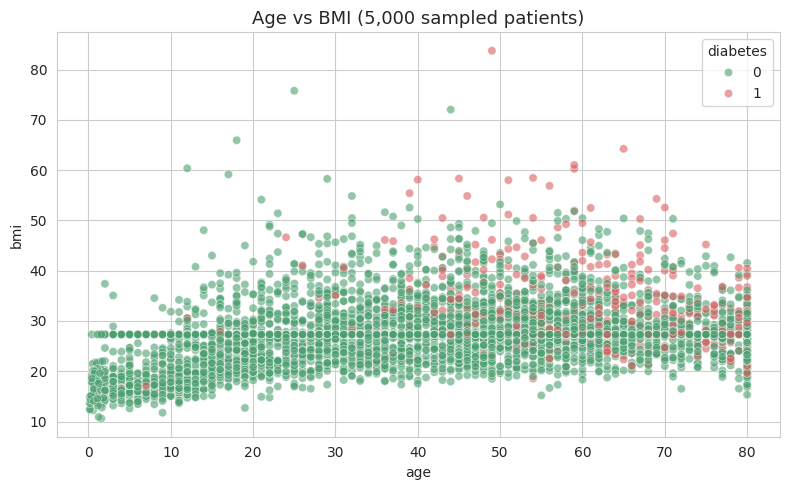

In [28]:
# Plot age against BMI coloured by diabetes status
sns.scatterplot(data=sample_df, x='age', y='bmi', hue='diabetes',
                palette=['#4C9F70', '#D95F5F'], alpha=0.6)
plt.title('Age vs BMI (5,000 sampled patients)')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_age_vs_bmi.png', dpi=150)
plt.show()

### 5.14 Correlation heatmap

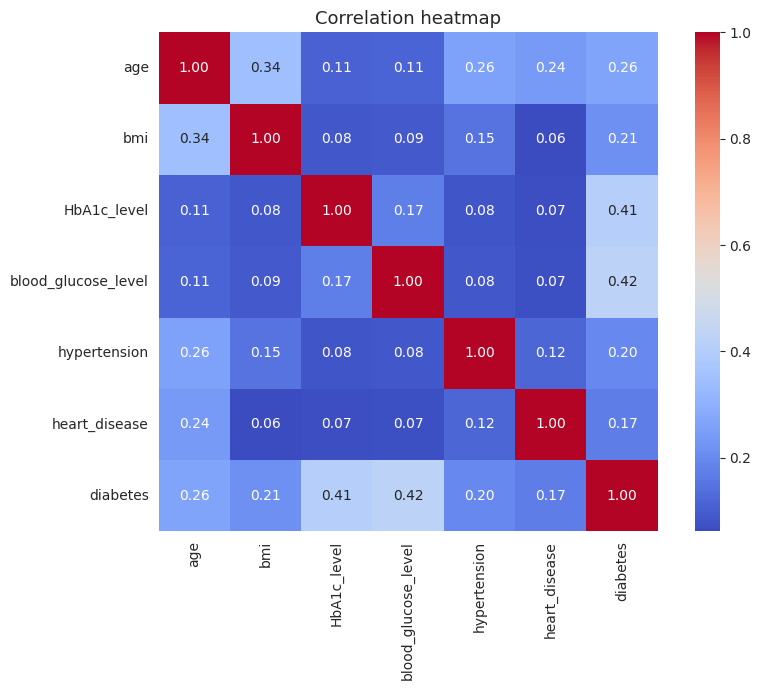

In [29]:
# Select the numerical and binary columns for correlation
corr_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level',
             'hypertension', 'heart_disease', 'diabetes']

# Plot the correlation matrix as a heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation heatmap')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_correlation_heatmap.png', dpi=150)
plt.show()

### 5.15 Correlation of each feature with diabetes

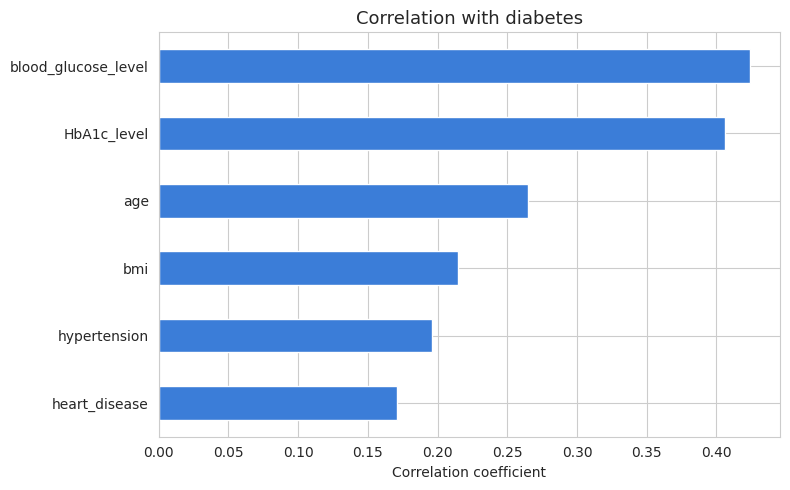

In [30]:
# Rank features by their correlation with the target
target_corr = df[corr_cols].corr()['diabetes'].drop('diabetes').sort_values()

# Plot the ranked correlations
target_corr.plot.barh(color='#3B7DD8')
plt.title('Correlation with diabetes')
plt.xlabel('Correlation coefficient')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/eda_target_correlation.png', dpi=150)
plt.show()

### 5.16 EDA key observations


## 6. Feature preparation and train/test split

### 6.1 Separating features and target

In [31]:
# Split the data into input features (X) and the target (y)
X = df.drop('diabetes', axis=1)
y = df['diabetes']

# Store the exact feature order, which the Flask app must follow
feature_columns = list(X.columns)
print('Feature order:', feature_columns)

Feature order: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']


### 6.2 Train/test split


In [32]:
# Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# Print the size and class balance of each set
print('Training set:', X_train.shape, '| diabetes rate:', round(y_train.mean() * 100, 2), '%')
print('Testing set :', X_test.shape, '| diabetes rate:', round(y_test.mean() * 100, 2), '%')

Training set: (76902, 8) | diabetes rate: 8.82 %
Testing set : (19226, 8) | diabetes rate: 8.82 %


### 6.3 Preprocessing pipeline


In [33]:
# Define the column groups
numeric_features = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
categorical_features = ['gender', 'smoking_history']
binary_features = ['hypertension', 'heart_disease']

# Build a function that creates the preprocessing step for a given set of columns
def build_preprocessor(num_cols, cat_cols, bin_cols):
    return ColumnTransformer(transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('bin', 'passthrough', bin_cols)])

# Create the preprocessor used by every model
preprocessor = build_preprocessor(numeric_features, categorical_features, binary_features)

### 6.4 Handling class imbalance


In [34]:
# Calculate the ratio of negative to positive cases for XGBoost
neg_to_pos = (y_train == 0).sum() / (y_train == 1).sum()
print('Negative to positive ratio:', round(neg_to_pos, 2))

Negative to positive ratio: 10.33


## 7. Model building
Five classification models are trained on the same training data and compared.

### 7.1 Defining the models


In [35]:
# Define the five models with class-imbalance handling
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced',
                                              random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, class_weight='balanced',
                                            random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced',
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'SVM (Linear, calibrated)': CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE), cv=3),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                             scale_pos_weight=neg_to_pos, eval_metric='logloss',
                             n_jobs=-1, random_state=RANDOM_STATE)}

### 7.2 Training the models

In [36]:
# Train every model inside a pipeline (preprocessing + model)
trained = {}
for name, model in models.items():
    start = time.time()
    pipe = Pipeline([('preprocessor', clone(preprocessor)), ('model', model)])
    pipe.fit(X_train, y_train)
    trained[name] = pipe
    print(f'{name:28s} trained in {time.time() - start:5.1f} seconds')

Logistic Regression          trained in   0.3 seconds
Decision Tree                trained in   0.3 seconds
Random Forest                trained in   7.2 seconds
SVM (Linear, calibrated)     trained in   0.7 seconds
XGBoost                      trained in   3.7 seconds


## 8. Model evaluation and comparison

### 8.1 Evaluating all models on the test set


In [37]:
# Calculate the evaluation metrics for every trained model
results = []
predictions = {}
for name, pipe in trained.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    predictions[name] = (y_pred, y_prob)
    results.append({'Model': name,
                    'Accuracy': accuracy_score(y_test, y_pred),
                    'Precision': precision_score(y_test, y_pred),
                    'Recall': recall_score(y_test, y_pred),
                    'F1-score': f1_score(y_test, y_pred),
                    'ROC-AUC': roc_auc_score(y_test, y_prob)})

# Show the results as a table sorted by F1-score
results_df = pd.DataFrame(results).sort_values('F1-score', ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,"SVM (Linear, calibrated)",0.9579,0.8495,0.6356,0.7272,0.9595
1,XGBoost,0.9086,0.4902,0.8974,0.6340,0.9764
2,Random Forest,0.9093,0.4922,0.8880,0.6333,0.9744
3,Decision Tree,0.8871,0.4330,0.9045,0.5856,0.9710
4,Logistic Regression,0.8852,0.4266,0.8762,0.5739,0.9596


### 8.2 Metric comparison chart

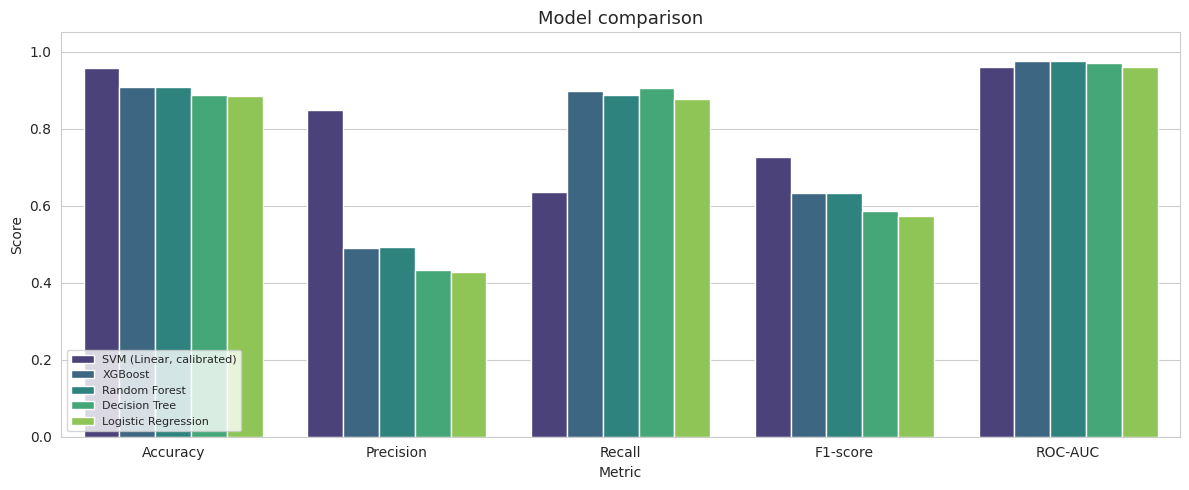

In [38]:
# Reshape the results and plot all metrics side by side
plot_df = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x='Metric', y='Score', hue='Model', palette='viridis')
plt.title('Model comparison')
plt.ylim(0, 1.05)
plt.legend(loc='lower left', fontsize=8)

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/model_comparison.png', dpi=150)
plt.show()

### 8.3 Confusion matrices

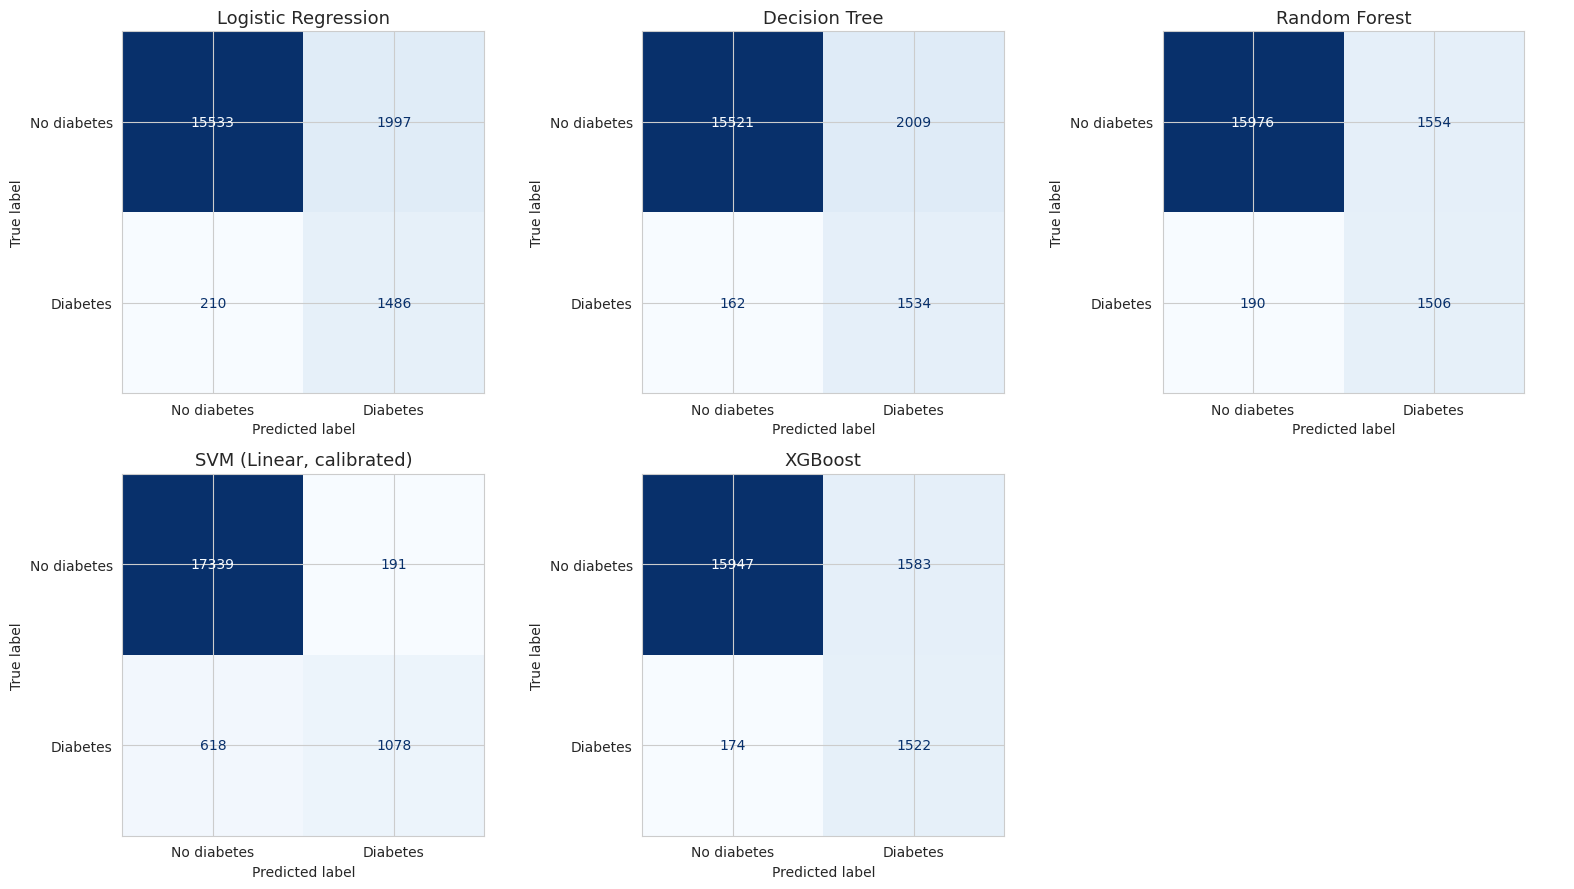

In [39]:
# Plot one confusion matrix for each model
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, (y_pred, _)) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=['No diabetes', 'Diabetes']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

# Hide the unused sixth subplot
axes.ravel()[-1].axis('off')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/confusion_matrices_all_models.png', dpi=150)
plt.show()

### 8.4 ROC curves

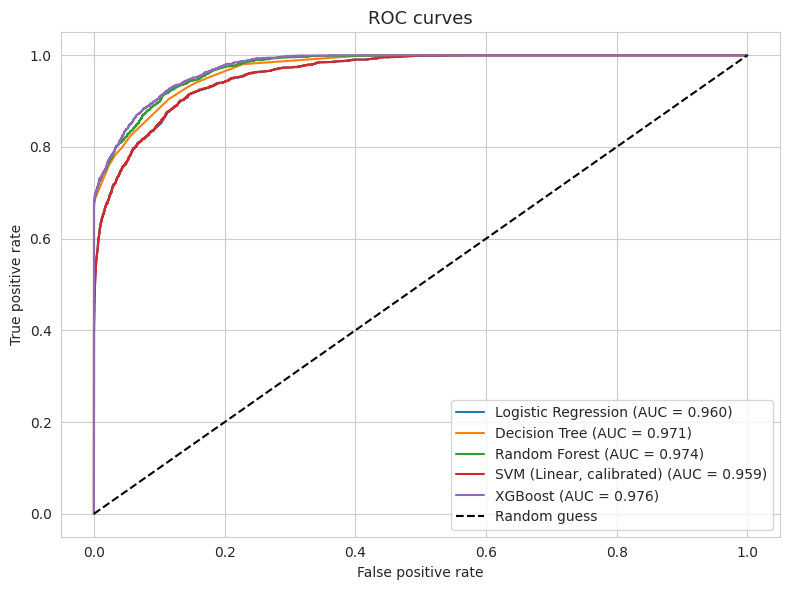

In [40]:
# Plot the ROC curve of every model on one chart
plt.figure(figsize=(8, 6))
for name, (_, y_prob) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})')

# Add the random-guess reference line and labels
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves')
plt.legend(loc='lower right')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/roc_curves_all_models.png', dpi=150)
plt.show()

### 8.5 Cross-validation check


In [41]:
# Run 5-fold stratified cross-validation (F1) for every model
from sklearn.model_selection import cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    pipe = Pipeline([('preprocessor', clone(preprocessor)), ('model', clone(model))])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
    cv_rows.append({'Model': name, 'CV F1 mean': scores.mean(), 'CV F1 std': scores.std()})

# Show the cross-validation results
pd.DataFrame(cv_rows).round(4)

,Model,CV F1 mean,CV F1 std
0,Logistic Regression,0.5801,0.0073
1,Decision Tree,0.5870,0.0105
2,Random Forest,0.6484,0.0043
3,"SVM (Linear, calibrated)",0.7261,0.0063
4,XGBoost,0.6457,0.0060


## 9. Best model selection and hyperparameter tuning

### 9.1 Selecting the best model


In [42]:
# Pick the model with the highest F1-score (ROC-AUC breaks ties)
best_row = results_df.sort_values(['F1-score', 'ROC-AUC'], ascending=False).iloc[0]
best_name = best_row['Model']
print('Best model before tuning:', best_name)
print(best_row.drop('Model').astype(float).round(4).to_string())

Best model before tuning: SVM (Linear, calibrated)
Accuracy     0.9579
Precision    0.8495
Recall       0.6356
F1-score     0.7272
ROC-AUC      0.9595


### 9.2 Tuning the best model


In [43]:
# Define the search space for each model (only the selected model is tuned)
param_spaces = {
    'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10, 100]},
    'Decision Tree': {'model__max_depth': [4, 6, 8, 10, 12],
                      'model__min_samples_leaf': [1, 5, 20, 50]},
    'Random Forest': {'model__n_estimators': [100, 200, 300],
                      'model__max_depth': [8, 12, 16],
                      'model__min_samples_leaf': [1, 5, 10]},
    'SVM (Linear, calibrated)': {'model__estimator__C': [0.01, 0.1, 1, 10]},
    'XGBoost': {'model__n_estimators': [200, 300, 400],
                'model__max_depth': [3, 5, 7],
                'model__learning_rate': [0.05, 0.1, 0.2]}}

# Work out how many random combinations to try
space = param_spaces[best_name]
grid_size = int(np.prod([len(v) for v in space.values()]))
n_iter = min(8, grid_size)

# Run the randomised search on the training data only
search = RandomizedSearchCV(trained[best_name], space, n_iter=n_iter, scoring='f1',
                            cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                            n_jobs=-1, random_state=RANDOM_STATE)
search.fit(X_train, y_train)

# Display the best parameters and cross-validated F1
print('Best parameters:', search.best_params_)
print('Best CV F1     :', round(search.best_score_, 4))

Best parameters: {'model__estimator__C': 0.01}
Best CV F1     : 0.7252


### 9.3 Comparing the default and tuned model


In [44]:
# Get the tuned pipeline
tuned_pipe = search.best_estimator_

# Calculate the test scores of the default and tuned versions
default_pipe = trained[best_name]
compare = []
for label, pipe in [('Default', default_pipe), ('Tuned', tuned_pipe)]:
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    compare.append({'Version': label,
                    'Accuracy': accuracy_score(y_test, y_pred),
                    'Precision': precision_score(y_test, y_pred),
                    'Recall': recall_score(y_test, y_pred),
                    'F1-score': f1_score(y_test, y_pred),
                    'ROC-AUC': roc_auc_score(y_test, y_prob)})
compare_df = pd.DataFrame(compare)

# Keep the better version as the final model
final_is_tuned = compare_df.loc[1, 'F1-score'] >= compare_df.loc[0, 'F1-score']
final_pipeline = tuned_pipe if final_is_tuned else default_pipe
print('Final model version:', 'Tuned' if final_is_tuned else 'Default')
compare_df.round(4)

Final model version: Tuned


,Version,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Default,0.9579,0.8495,0.6356,0.7272,0.9595
1,Tuned,0.9580,0.8502,0.6356,0.7274,0.9595


## 10. Final model evaluation

### 10.1 Classification report

In [45]:
# Get the final predictions and probabilities
final_pred = final_pipeline.predict(X_test)
final_prob = final_pipeline.predict_proba(X_test)[:, 1]

# Print the full classification report
print(f'Final model: {best_name}\n')
print(classification_report(y_test, final_pred, target_names=['No diabetes', 'Diabetes']))

Final model: SVM (Linear, calibrated)

              precision    recall  f1-score   support

 No diabetes       0.97      0.99      0.98     17530
    Diabetes       0.85      0.64      0.73      1696

    accuracy                           0.96     19226
   macro avg       0.91      0.81      0.85     19226
weighted avg       0.96      0.96      0.96     19226



### 10.2 Confusion matrix of the final model

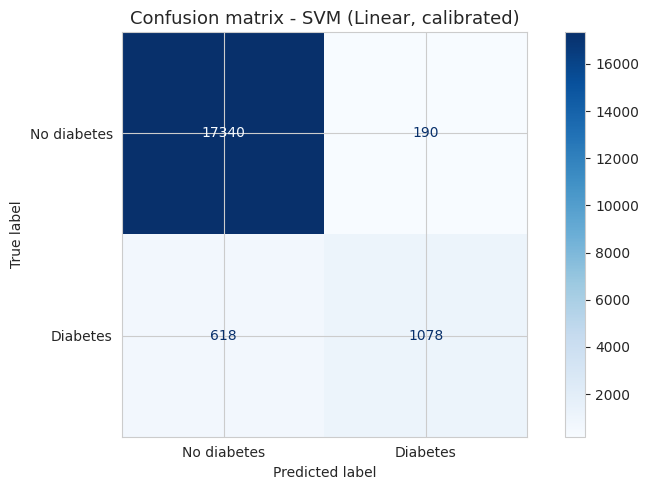

In [46]:
# Plot the confusion matrix of the final model
ConfusionMatrixDisplay(confusion_matrix(y_test, final_pred),
                       display_labels=['No diabetes', 'Diabetes']).plot(cmap='Blues')
plt.title(f'Confusion matrix - {best_name}')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/final_confusion_matrix.png', dpi=150)
plt.show()

### 10.3 ROC and precision-recall curves of the final model

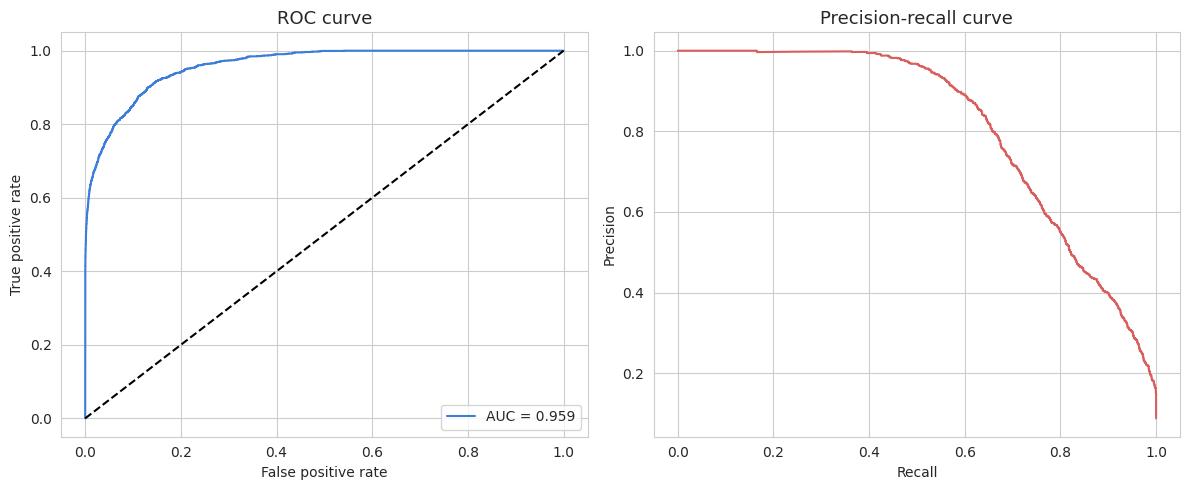

In [47]:
# Plot the ROC curve and the precision-recall curve side by side
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
fpr, tpr, _ = roc_curve(y_test, final_prob)
ax[0].plot(fpr, tpr, color='#3B7DD8', label=f'AUC = {roc_auc_score(y_test, final_prob):.3f}')
ax[0].plot([0, 1], [0, 1], 'k--')
ax[0].set_xlabel('False positive rate')
ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC curve')
ax[0].legend()

# Draw the precision-recall curve
prec, rec, _ = precision_recall_curve(y_test, final_prob)
ax[1].plot(rec, prec, color='#D95F5F')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-recall curve')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/final_roc_pr_curves.png', dpi=150)
plt.show()

### 10.4 Effect of the decision threshold


In [48]:
# Calculate precision, recall and F1 at several thresholds
threshold_rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (final_prob >= t).astype(int)
    threshold_rows.append({'Threshold': t,
                           'Precision': precision_score(y_test, pred_t),
                           'Recall': recall_score(y_test, pred_t),
                           'F1-score': f1_score(y_test, pred_t)})

# Display the threshold table
pd.DataFrame(threshold_rows).round(4)

,Threshold,Precision,Recall,F1-score
0,0.3,0.6964,0.7170,0.7066
1,0.4,0.7816,0.6710,0.7221
2,0.5,0.8502,0.6356,0.7274
3,0.6,0.8980,0.5920,0.7136
4,0.7,0.9415,0.5407,0.6869


### 10.5 Distribution of predicted risk probabilities


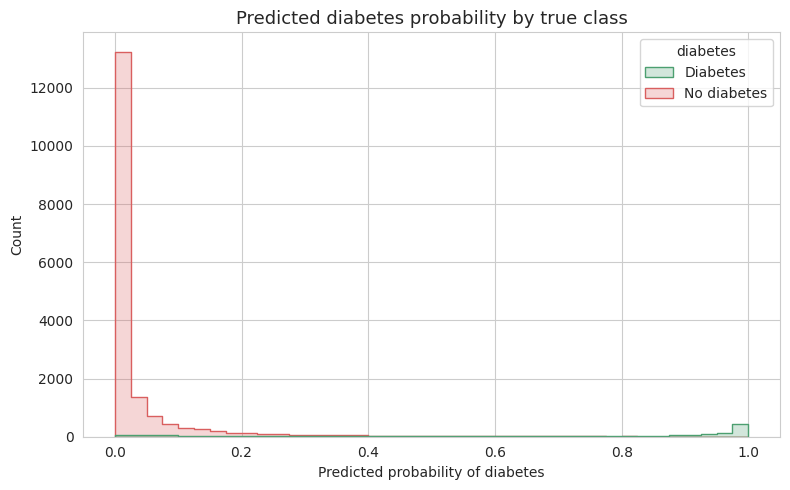

In [49]:
# Plot the predicted probabilities for both true classes
sns.histplot(x=final_prob, hue=y_test.map({0: 'No diabetes', 1: 'Diabetes'}), bins=40,
             palette=['#4C9F70', '#D95F5F'], element='step')
plt.title('Predicted diabetes probability by true class')
plt.xlabel('Predicted probability of diabetes')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/final_probability_distribution.png', dpi=150)
plt.show()

## 11. Feature importance


In [50]:
# Use a sample of the test set to keep the calculation fast
X_imp = X_test.sample(min(8000, len(X_test)), random_state=RANDOM_STATE)
y_imp = y_test.loc[X_imp.index]

# Calculate permutation importance on the raw input columns
perm = permutation_importance(final_pipeline, X_imp, y_imp, scoring='roc_auc',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

# Store the result in a sorted table
importance_df = (pd.DataFrame({'Feature': X_imp.columns, 'Importance': perm.importances_mean})
                 .sort_values('Importance', ascending=False).reset_index(drop=True))
importance_df.round(4)

,Feature,Importance
0,HbA1c_level,0.1469
1,blood_glucose_level,0.0553
2,age,0.0310
3,bmi,0.0113
4,smoking_history,0.0010
5,hypertension,0.0006
6,heart_disease,0.0004
7,gender,-0.0003


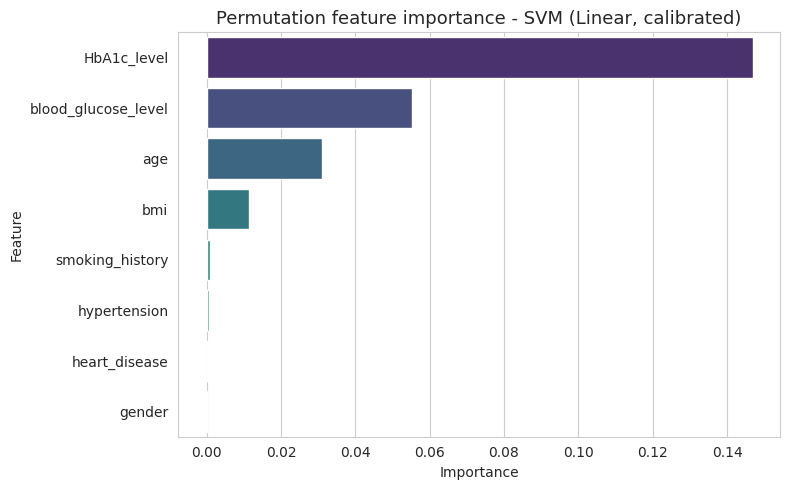

In [51]:
# Plot the feature importance ranking
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title(f'Permutation feature importance - {best_name}')

# Save and show the figure
plt.tight_layout()
plt.savefig('outputs/plots/feature_importance.png', dpi=150)
plt.show()

## 12. Dependence on HbA1c and blood glucose (additional check)


In [52]:
# Build a preprocessor without HbA1c and blood glucose
reduced_pre = build_preprocessor(['age', 'bmi'], categorical_features, binary_features)

# Train the same model type on the reduced feature set
reduced_pipe = Pipeline([('preprocessor', reduced_pre),
                         ('model', clone(final_pipeline.named_steps['model']))])
reduced_cols = [c for c in feature_columns if c not in ['HbA1c_level', 'blood_glucose_level']]
reduced_pipe.fit(X_train[reduced_cols], y_train)

# Compare the full model with the reduced model
red_pred = reduced_pipe.predict(X_test[reduced_cols])
red_prob = reduced_pipe.predict_proba(X_test[reduced_cols])[:, 1]
ablation_df = pd.DataFrame([
    {'Feature set': 'All features', 'Accuracy': accuracy_score(y_test, final_pred),
     'Precision': precision_score(y_test, final_pred), 'Recall': recall_score(y_test, final_pred),
     'F1-score': f1_score(y_test, final_pred), 'ROC-AUC': roc_auc_score(y_test, final_prob)},
    {'Feature set': 'Without HbA1c and glucose', 'Accuracy': accuracy_score(y_test, red_pred),
     'Precision': precision_score(y_test, red_pred), 'Recall': recall_score(y_test, red_pred),
     'F1-score': f1_score(y_test, red_pred), 'ROC-AUC': roc_auc_score(y_test, red_prob)}])
ablation_df.round(4)

,Feature set,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,All features,0.9580,0.8502,0.6356,0.7274,0.9595
1,Without HbA1c and glucose,0.9116,0.4903,0.0596,0.1062,0.8230


.

## 13. Saving the model files for the Flask application

### 13.1 Saving the final model pipeline as a `.pkl` file


In [53]:
# Save the complete pipeline with joblib
joblib.dump(final_pipeline, 'outputs/diabetes_model.pkl')

# Show the size of the saved file
print('Saved: outputs/diabetes_model.pkl')
print('Size  :', round(os.path.getsize('outputs/diabetes_model.pkl') / 1024 / 1024, 2), 'MB')

Saved: outputs/diabetes_model.pkl
Size  : 0.01 MB


### 13.2 Saving the model metadata


In [54]:
# Collect the final test metrics
final_metrics = {'accuracy': accuracy_score(y_test, final_pred),
                 'precision': precision_score(y_test, final_pred),
                 'recall': recall_score(y_test, final_pred),
                 'f1_score': f1_score(y_test, final_pred),
                 'roc_auc': roc_auc_score(y_test, final_prob)}

# Build the metadata dictionary
metadata = {
    'model_name': best_name,
    'tuned': bool(final_is_tuned),
    'sklearn_version': sklearn.__version__,
    'feature_order': feature_columns,
    'categorical_values': {'gender': sorted(df['gender'].unique().tolist()),
                           'smoking_history': sorted(df['smoking_history'].unique().tolist())},
    'binary_features': binary_features,
    'numeric_ranges': {col: {'min': float(df[col].min()), 'max': float(df[col].max())}
                       for col in numeric_features},
    'threshold': 0.5,
    'risk_bands': {'low_below': 0.30, 'high_from': 0.60},
    'metrics': {k: round(float(v), 4) for k, v in final_metrics.items()},
    'training_rows': int(len(X_train)),
    'test_rows': int(len(X_test)),
    'target_labels': {'0': 'No diabetes', '1': 'Diabetes'}}

# Write the metadata to a JSON file
with open('outputs/model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

# Print the metadata for checking
print(json.dumps(metadata, indent=2))

{
  "model_name": "SVM (Linear, calibrated)",
  "tuned": true,
  "sklearn_version": "1.6.1",
  "feature_order": [
    "gender",
    "age",
    "hypertension",
    "heart_disease",
    "smoking_history",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
  ],
  "categorical_values": {
    "gender": [
      "Female",
      "Male"
    ],
    "smoking_history": [
      "No Info",
      "current",
      "ever",
      "former",
      "never",
      "not current"
    ]
  },
  "binary_features": [
    "hypertension",
    "heart_disease"
  ],
  "numeric_ranges": {
    "age": {
      "min": 0.08,
      "max": 80.0
    },
    "bmi": {
      "min": 10.01,
      "max": 95.69
    },
    "HbA1c_level": {
      "min": 3.5,
      "max": 9.0
    },
    "blood_glucose_level": {
      "min": 80.0,
      "max": 300.0
    }
  },
  "threshold": 0.5,
  "risk_bands": {
    "low_below": 0.3,
    "high_from": 0.6
  },
  "metrics": {
    "accuracy": 0.958,
    "precision": 0.8502,
    "recall": 0.6356,
    "

### 13.3 Saving the model comparison table

In [55]:
# Save the comparison of all models and the feature importance as CSV files
results_df.round(4).to_csv('outputs/model_comparison.csv', index=False)
importance_df.round(4).to_csv('outputs/feature_importance.csv', index=False)
print('Saved: model_comparison.csv and feature_importance.csv')

Saved: model_comparison.csv and feature_importance.csv


### 13.4 Testing the saved model like the Flask app will use it



In [56]:
# Load the saved model from disk
loaded_model = joblib.load('outputs/diabetes_model.pkl')

# Create two sample patients using the same column names as the form
samples = pd.DataFrame([
    {'gender': 'Female', 'age': 25, 'hypertension': 0, 'heart_disease': 0,
     'smoking_history': 'never', 'bmi': 22.0, 'HbA1c_level': 4.8, 'blood_glucose_level': 90},
    {'gender': 'Male', 'age': 65, 'hypertension': 1, 'heart_disease': 1,
     'smoking_history': 'former', 'bmi': 34.0, 'HbA1c_level': 7.5, 'blood_glucose_level': 220}
])[feature_columns]

# Predict the class and probability for each sample
samples['predicted_class'] = loaded_model.predict(samples[feature_columns])
samples['risk_probability'] = loaded_model.predict_proba(samples[feature_columns])[:, 1].round(4)
samples

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,predicted_class,risk_probability
0,Female,25,0,0,never,22.0,4.8,90,0,0.0001
1,Male,65,1,1,former,34.0,7.5,220,1,0.9959


### 13.5 Downloading all output files

In [58]:
# Zip the outputs folder (model, metadata, tables and plots)
shutil.make_archive('diabetes_model_files', 'zip', 'outputs')
print('Created: diabetes_model_files.zip')

# Download the zip file when running in Google Colab
try:
    from google.colab import files
    files.download('diabetes_model_files.zip')
except ImportError:
    print('Not running in Colab - find the zip in the notebook folder')

Created: diabetes_model_files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>